In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go

print("All libraries imported successfully!")


All libraries imported successfully!


In [2]:

df = pd.read_csv("cleaned_sales_data.csv")

print("Dataset Loaded Successfully!")
print("Dataset Shape:", df.shape)

display(df.head())
print("\nColumn Names:")
print(df.columns.tolist())


Dataset Loaded Successfully!
Dataset Shape: (1000, 17)


,Invoice ID,Branch,City,Customer type,Gender,Product line,Unit price,Quantity,Tax 5%,Total,Date,Time,Payment,Cost of goods sold,Gross margin percentage,Gross income,Customer stratification rating
0,750-67-8428,A,Yangon,Member,Female,Health and beauty,74.69,7,26.1415,548.9715,2019-01-05,13:08,Ewallet,522.83,4.761905,26.1415,9.1
1,226-31-3081,C,Naypyitaw,Normal,Female,Electronic accessories,15.28,5,3.8200,80.2200,2019-03-08,10:29,Cash,76.40,4.761905,3.8200,9.6
2,631-41-3108,A,Yangon,Normal,Male,Home and lifestyle,46.33,7,16.2155,340.5255,2019-03-03,13:23,Credit card,324.31,4.761905,16.2155,7.4
3,123-19-1176,A,Yangon,Member,Male,Health and beauty,58.22,8,23.2880,489.0480,2019-01-27,20:33,Ewallet,465.76,4.761905,23.2880,8.4
4,373-73-7910,A,Yangon,Normal,Male,Sports and travel,86.31,7,30.2085,634.3785,2019-02-08,10:37,Ewallet,604.17,4.761905,30.2085,5.3



Column Names:
['Invoice ID', 'Branch', 'City', 'Customer type', 'Gender', 'Product line', 'Unit price', 'Quantity', 'Tax 5%', 'Total', 'Date', 'Time', 'Payment', 'Cost of goods sold', 'Gross margin percentage', 'Gross income', 'Customer stratification rating']


In [3]:

# KPI Calculations

total_sales = df['Total'].sum()
total_profit = df['Gross income'].sum()
total_orders = df['Invoice ID'].nunique()
total_quantity = df['Quantity'].sum()
average_sales = df['Total'].mean()

print("========== SALES DASHBOARD ==========")
print("Total Sales:", round(total_sales, 2))
print("Total Gross Income:", round(total_profit, 2))
print("Total Orders:", total_orders)
print("Total Quantity Sold:", total_quantity)
print("Average Sales:", round(average_sales, 2))
print("=====================================")


========== SALES DASHBOARD ==========
Total Sales: 322966.75
Total Gross Income: 15379.37
Total Orders: 1000
Total Quantity Sold: 5510
Average Sales: 322.97


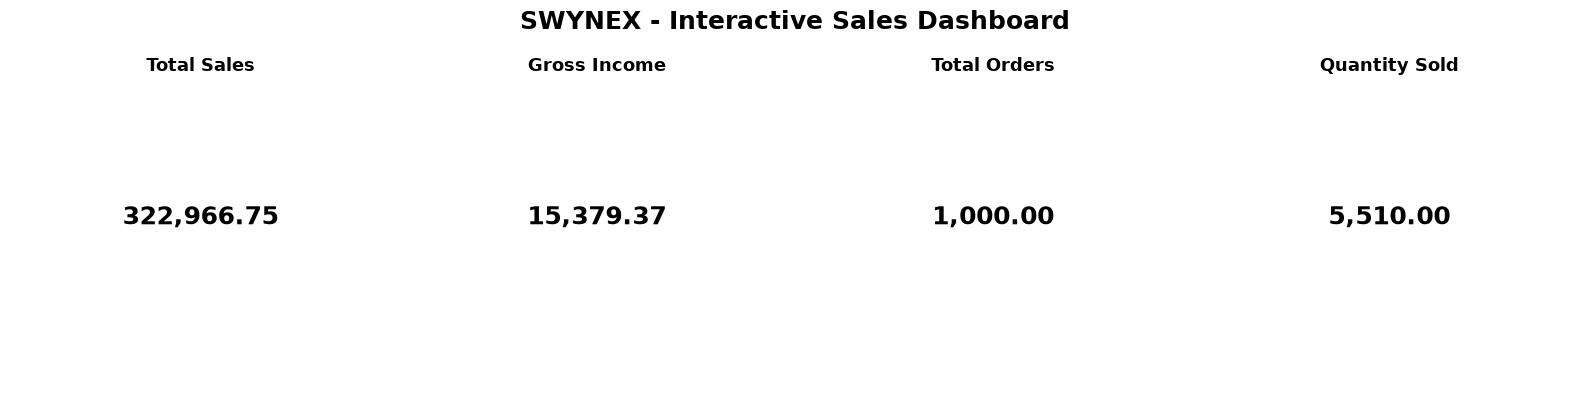

In [4]:

import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 4, figsize=(16, 4))

kpis = [
    ("Total Sales", total_sales),
    ("Gross Income", total_profit),
    ("Total Orders", total_orders),
    ("Quantity Sold", total_quantity)
]

for ax, (title, value) in zip(axes, kpis):
    ax.text(0.5, 0.55, f"{value:,.2f}",
            ha='center', va='center',
            fontsize=18, fontweight='bold')
    ax.set_title(title, fontsize=13, fontweight='bold')
    ax.axis('off')

plt.suptitle("SWYNEX - Interactive Sales Dashboard",
             fontsize=18, fontweight='bold')
plt.tight_layout()
plt.show()


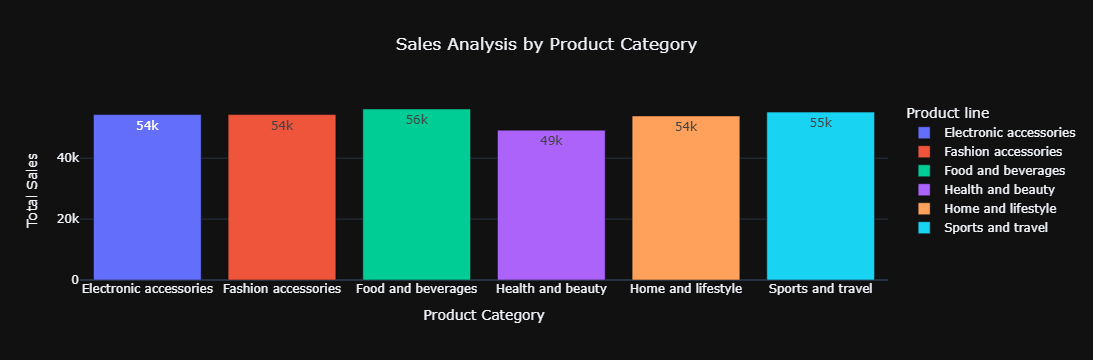

In [5]:

# Category-wise Sales Analysis

category_sales = df.groupby('Product line')['Total'].sum().reset_index()

fig = px.bar(
    category_sales,
    x='Product line',
    y='Total',
    color='Product line',
    title='Sales Analysis by Product Category',
    text_auto='.2s'
)

fig.update_layout(
    template='plotly_dark',
    xaxis_title='Product Category',
    yaxis_title='Total Sales',
    title_x=0.5
)

fig.show()


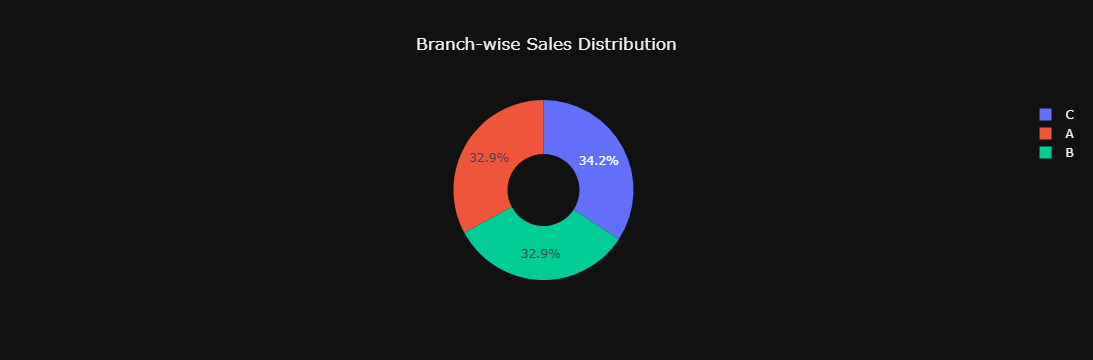

In [6]:

branch_sales = df.groupby('Branch')['Total'].sum().reset_index()

fig = px.pie(
    branch_sales,
    names='Branch',
    values='Total',
    title='Branch-wise Sales Distribution',
    hole=0.4
)

fig.update_layout(
    template='plotly_dark',
    title_x=0.5
)

fig.show()


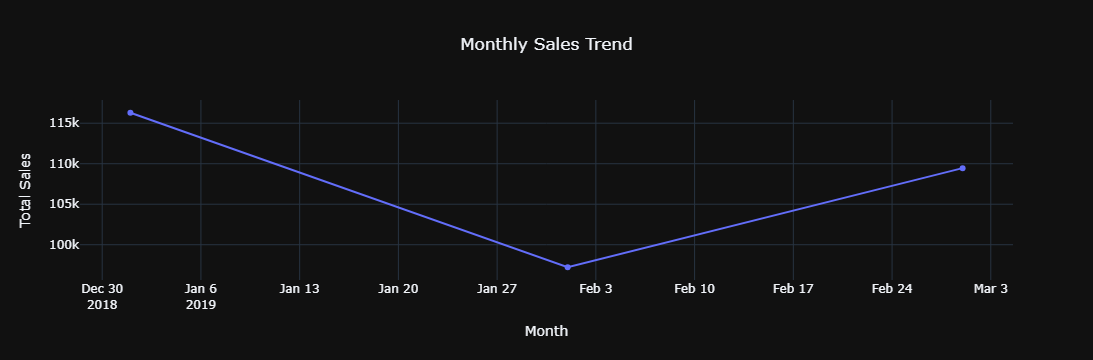

In [7]:

# Convert Date column into datetime
df['Date'] = pd.to_datetime(df['Date'])

# Extract Month
df['Month'] = df['Date'].dt.to_period('M').astype(str)

# Monthly Sales
monthly_sales = df.groupby('Month')['Total'].sum().reset_index()

# Create Interactive Line Chart
fig = px.line(
    monthly_sales,
    x='Month',
    y='Total',
    markers=True,
    title='Monthly Sales Trend',
    template='plotly_dark'
)

fig.update_layout(
    title_x=0.5,
    xaxis_title='Month',
    yaxis_title='Total Sales'
)

fig.show()


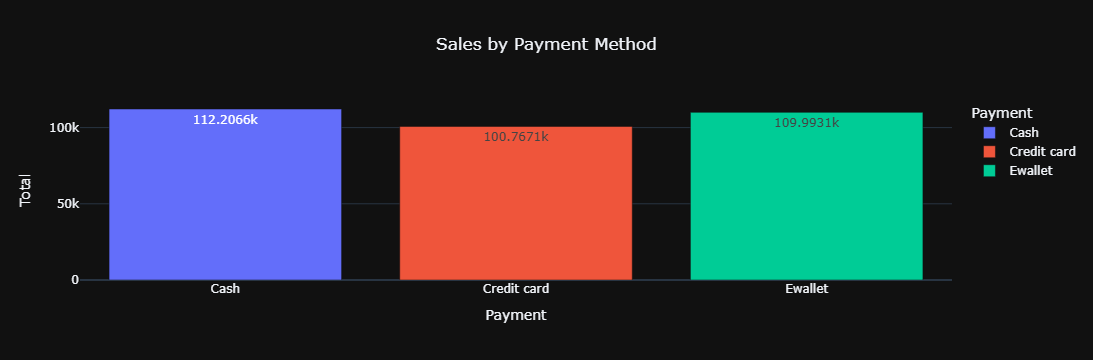

In [8]:

payment_sales = df.groupby('Payment')['Total'].sum().reset_index()

fig = px.bar(
    payment_sales,
    x='Payment',
    y='Total',
    color='Payment',
    title='Sales by Payment Method',
    template='plotly_dark',
    text_auto=True
)

fig.update_layout(title_x=0.5)
fig.show()


In [9]:

import ipywidgets as widgets
from IPython.display import display, clear_output, HTML

# Create interactive filters
branch_filter = widgets.Dropdown(
    options=['All'] + sorted(df['Branch'].dropna().astype(str).unique().tolist()),
    description='Branch:'
)

city_filter = widgets.Dropdown(
    options=['All'] + sorted(df['City'].dropna().astype(str).unique().tolist()),
    description='City:'
)

category_filter = widgets.Dropdown(
    options=['All'] + sorted(df['Product line'].dropna().astype(str).unique().tolist()),
    description='Category:'
)

payment_filter = widgets.Dropdown(
    options=['All'] + sorted(df['Payment'].dropna().astype(str).unique().tolist()),
    description='Payment:'
)

output = widgets.Output()

def update_dashboard(branch, city, category, payment):
    with output:
        clear_output(wait=True)

        filtered = df.copy()

        if branch != 'All':
            filtered = filtered[filtered['Branch'].astype(str) == branch]

        if city != 'All':
            filtered = filtered[filtered['City'].astype(str) == city]

        if category != 'All':
            filtered = filtered[filtered['Product line'].astype(str) == category]

        if payment != 'All':
            filtered = filtered[filtered['Payment'].astype(str) == payment]

        if filtered.empty:
            display(HTML("<h3>No data available for selected filters.</h3>"))
            return

        sales = filtered['Total'].sum()
        income = filtered['Gross income'].sum()
        orders = filtered['Invoice ID'].nunique()
        quantity = filtered['Quantity'].sum()

        display(HTML(f"""
        <h2>SWYNEX Interactive Sales Dashboard</h2>
        <h3>Total Sales: {sales:,.2f}</h3>
        <h3>Gross Income: {income:,.2f}</h3>
        <h3>Total Orders: {orders:,}</h3>
        <h3>Quantity Sold: {quantity:,}</h3>
        """))

        category_data = filtered.groupby(
            'Product line'
        )['Total'].sum().reset_index()

        fig1 = px.bar(
            category_data,
            x='Product line',
            y='Total',
            color='Product line',
            title='Filtered Category-wise Sales',
            template='plotly_dark'
        )
        display(fig1)

        payment_data = filtered.groupby(
            'Payment'
        )['Total'].sum().reset_index()

        fig2 = px.pie(
            payment_data,
            names='Payment',
            values='Total',
            title='Filtered Payment Distribution',
            template='plotly_dark',
            hole=0.4
        )
        display(fig2)

controls = widgets.VBox([
    widgets.HBox([branch_filter, city_filter]),
    widgets.HBox([category_filter, payment_filter])
])

dashboard = widgets.interactive_output(
    update_dashboard,
    {
        'branch': branch_filter,
        'city': city_filter,
        'category': category_filter,
        'payment': payment_filter
    }
)

display(controls, output)


Output()

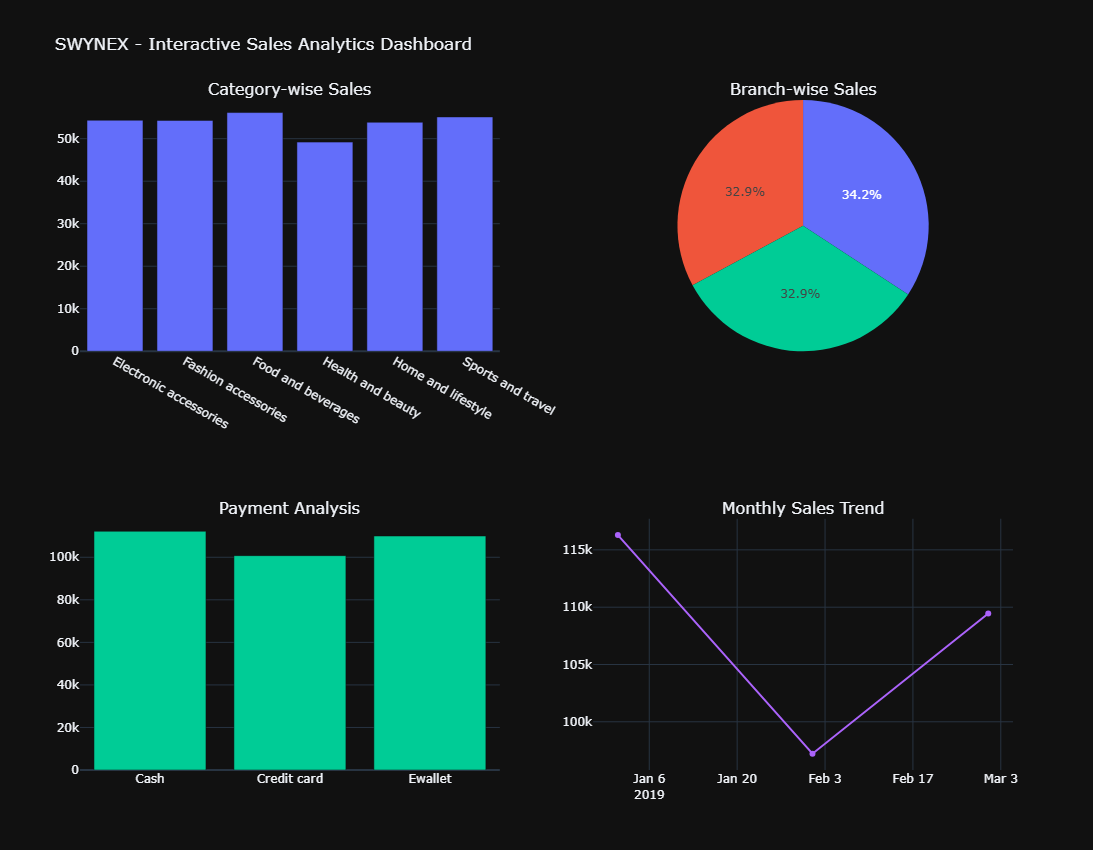

Dashboard HTML file saved successfully!


In [10]:

# Save interactive dashboard charts as HTML

import plotly.io as pio

category_data = df.groupby('Product line')['Total'].sum().reset_index()
branch_data = df.groupby('Branch')['Total'].sum().reset_index()
payment_data = df.groupby('Payment')['Total'].sum().reset_index()
monthly_data = df.groupby('Month')['Total'].sum().reset_index()

from plotly.subplots import make_subplots

fig = make_subplots(
    rows=2, cols=2,
    subplot_titles=(
        'Category-wise Sales',
        'Branch-wise Sales',
        'Payment Analysis',
        'Monthly Sales Trend'
    ),
    specs=[
        [{"type": "bar"}, {"type": "pie"}],
        [{"type": "bar"}, {"type": "scatter"}]
    ]
)

fig.add_trace(
    go.Bar(x=category_data['Product line'],
           y=category_data['Total'], name='Category Sales'),
    row=1, col=1
)

fig.add_trace(
    go.Pie(labels=branch_data['Branch'],
           values=branch_data['Total'], name='Branch Sales'),
    row=1, col=2
)

fig.add_trace(
    go.Bar(x=payment_data['Payment'],
           y=payment_data['Total'], name='Payment Sales'),
    row=2, col=1
)

fig.add_trace(
    go.Scatter(x=monthly_data['Month'],
               y=monthly_data['Total'],
               mode='lines+markers', name='Monthly Sales'),
    row=2, col=2
)

fig.update_layout(
    title='SWYNEX - Interactive Sales Analytics Dashboard',
    template='plotly_dark',
    height=850,
    showlegend=False
)

fig.write_html(
    'SWYNEX_Task3_Interactive_Dashboard.html',
    include_plotlyjs=True
)

fig.show()

print("Dashboard HTML file saved successfully!")


In [11]:

import os

print("Task 3 Project Files:")

for file in os.listdir():
    if "SWYNEX_Task3" in file:
        print("✅", file)


Task 3 Project Files:
✅ SWYNEX_Task3_Interactive_Dashboard.html
✅ SWYNEX_Task3_Interactive_Dashboard.ipynb
